### Machine Learning - Assignment 1: Unsupervised Learning | Exercise 2

**145873 - Sezer Tetik**

In [6]:
import matplotlib.pyplot as plt
import numpy as np

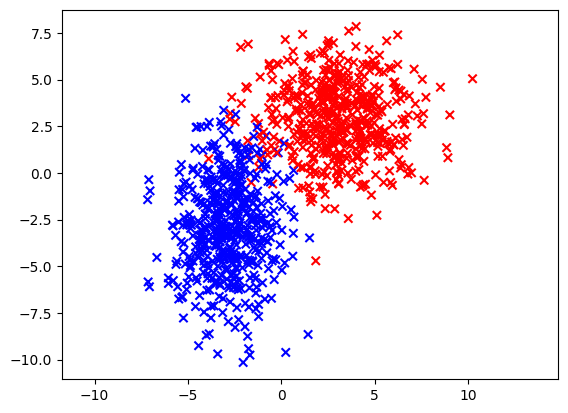

In [7]:
points = np.genfromtxt('data.csv', delimiter=',')

x = points[:, 0]
y = points[:, 1]
label = points[:, 2].astype(int) # 1 or 2

colors = np.array(['red', 'blue'])
plt.scatter(x, y, c=colors[label - 1], marker='x')
plt.axis("equal")
plt.show()

In [8]:
points_copy = points.copy()

distances = np.linalg.norm(
    points_copy[:, None, :] - points_copy[None, :, :],
    axis=2
)

print(len(distances), len(points))

while len(distances) > 2:
    np.fill_diagonal(distances, np.inf)
    i, j = np.unravel_index(np.argmin(distances), distances.shape)
    points_copy[i] = (points_copy[i] + points_copy[j]) / 2
    points_copy = np.delete(points_copy, j, axis=0)
    distances = np.linalg.norm(
        points_copy[:, None, :] - points_copy[None, :, :],
        axis=2
    )

points_copy

1000 1000


array([[ 2.89298655,  3.06201143,  1.17773438],
       [-0.79168258, -7.30447608,  1.96875   ]])

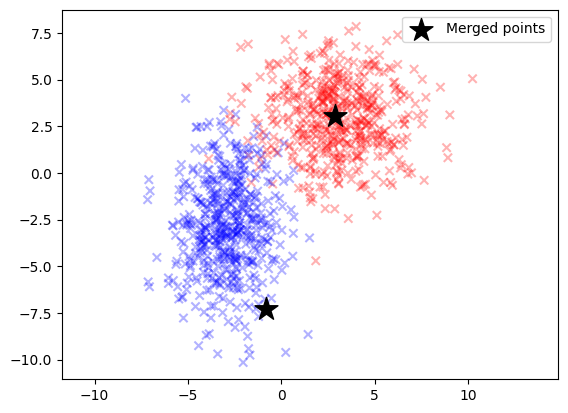

In [9]:
plt.scatter(x, y, c=colors[label - 1], marker='x', alpha=0.3)
plt.scatter(points_copy[:, 0], points_copy[:, 1], c='black', marker='*', s=300, label='Merged points')
plt.axis("equal")
plt.legend()
plt.show()

[[-2.95017935 -3.3294162 ]
 [ 2.49799631  2.8001512 ]] [449. 551.]


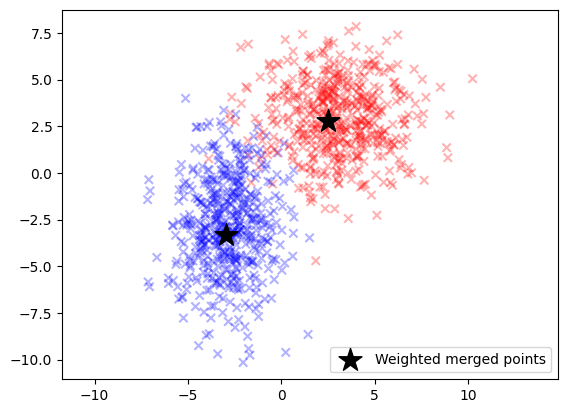

In [10]:
weighted_points = points[:, :2].copy()  # x, y only, no label
sizes = np.ones(len(weighted_points))  # how many original points each one represents

distances = np.linalg.norm(
    weighted_points[:, None, :] - weighted_points[None, :, :],
    axis=2
)

while len(distances) > 2:
    np.fill_diagonal(distances, np.inf)
    i, j = np.unravel_index(np.argmin(distances), distances.shape)
    weighted_points[i] = (sizes[i] * weighted_points[i] + sizes[j] * weighted_points[j]) / (sizes[i] + sizes[j])
    sizes[i] += sizes[j]
    weighted_points = np.delete(weighted_points, j, axis=0)
    sizes = np.delete(sizes, j)
    distances = np.linalg.norm(
        weighted_points[:, None, :] - weighted_points[None, :, :],
        axis=2
    )

print(weighted_points, sizes)

plt.scatter(x, y, c=colors[label - 1], marker='x', alpha=0.3)
plt.scatter(weighted_points[:, 0], weighted_points[:, 1], c='black', marker='*', s=300, label='Weighted merged points')
plt.axis("equal")
plt.legend()
plt.show()